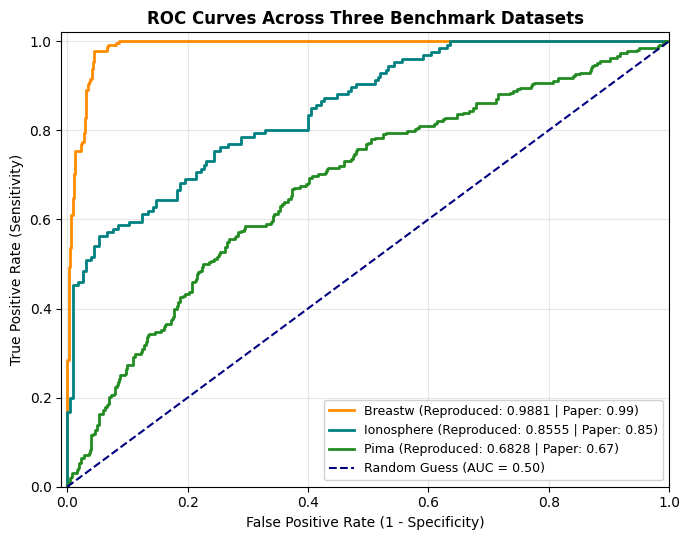


Dataset        Paper AUC      Reproduced Mean     Std Dev   
Breastw        0.99           0.9881              0.0012    
Ionosphere     0.85           0.8555              0.0059    
Pima           0.67           0.6828              0.0103    


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import roc_auc_score, roc_curve

# ==============================================================================
# 1. Theoretical BST Constant: c(n)
# ==============================================================================
def c_factor(n):
    if n <= 1:
        return 0.0
    if n == 2:
        return 1.0
    return 2.0 * (np.log(n - 1) + 0.5772156649) - (2.0 * (n - 1) / n)

# ==============================================================================
# 2. Isolation Tree (iTree) - Algorithms 2 & 3
# ==============================================================================
class Node:
    def __init__(self, left=None, right=None, split_attr=None, split_val=None, size=0, is_leaf=False):
        self.left = left
        self.right = right
        self.split_attr = split_attr
        self.split_val = split_val
        self.size = size
        self.is_leaf = is_leaf

def make_itree(X, current_height, height_limit):
    n_samples, n_features = X.shape
    if current_height >= height_limit or n_samples <= 1 or np.all(X == X[0, :]):
        return Node(size=n_samples, is_leaf=True)

    attr = np.random.randint(0, n_features)
    feat_min, feat_max = X[:, attr].min(), X[:, attr].max()
    if feat_min == feat_max:
        return Node(size=n_samples, is_leaf=True)

    split_val = np.random.uniform(feat_min, feat_max)
    left_mask = X[:, attr] < split_val
    return Node(
        left=make_itree(X[left_mask], current_height + 1, height_limit),
        right=make_itree(X[~left_mask], current_height + 1, height_limit),
        split_attr=attr,
        split_val=split_val
    )

def path_length(x, node, current_depth):
    if node.is_leaf:
        return current_depth + c_factor(node.size)
    if x[node.split_attr] < node.split_val:
        return path_length(x, node.left, current_depth + 1)
    return path_length(x, node.right, current_depth + 1)

# ==============================================================================
# 3. Isolation Forest Ensemble - Algorithm 1
# ==============================================================================
class IsolationForestFromScratch:
    def __init__(self, n_estimators=100, max_samples=256, random_state=42):
        self.n_estimators = n_estimators
        self.max_samples = max_samples
        self.random_state = random_state
        self.trees = []
        self.height_limit = int(np.ceil(np.log2(max_samples)))

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples = X.shape[0]
        subsample_size = min(self.max_samples, n_samples)
        self.c_subsample = c_factor(subsample_size)
        self.trees = []
        for _ in range(self.n_estimators):
            idx = np.random.choice(n_samples, subsample_size, replace=False)
            self.trees.append(make_itree(X[idx], 0, self.height_limit))
        return self

    def compute_anomaly_score(self, X):
        paths = np.zeros((X.shape[0], self.n_estimators))
        for t_idx, tree in enumerate(self.trees):
            for i in range(X.shape[0]):
                paths[i, t_idx] = path_length(X[i], tree, 0)
        return 2.0 ** (- (paths.mean(axis=1) / self.c_subsample))

# ==============================================================================
# 4. Benchmark Helper
# ==============================================================================
def evaluate_benchmark(X, y, name, paper_auc, n_trials=10):
    aucs = []
    for trial in range(n_trials):
        model = IsolationForestFromScratch(n_estimators=100, max_samples=256, random_state=trial)
        model.fit(X)
        scores = model.compute_anomaly_score(X)
        aucs.append(roc_auc_score(y, scores))

    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs)

    # Representative model for plotting the curve
    rep_model = IsolationForestFromScratch(n_estimators=100, max_samples=256, random_state=42)
    rep_model.fit(X)
    rep_scores = rep_model.compute_anomaly_score(X)

    return {
        'name': name,
        'paper_auc': paper_auc,
        'mean_auc': mean_auc,
        'std_auc': std_auc,
        'y': y,
        'scores': rep_scores
    }

# ==============================================================================
# 5. Load and Evaluate the 3 Benchmarks
# ==============================================================================
results = []

# 1. Breastw
b_data = fetch_openml(name='breast-w', version=1, as_frame=True)
df_b = b_data.frame.dropna()
feat_b = [c for c in df_b.columns if c not in ['Class', 'Sample_code_number']]
results.append(evaluate_benchmark(
    df_b[feat_b].astype(float).values,
    (df_b['Class'].astype(str) == 'malignant').astype(int).values,
    "Breastw", 0.99
))

# 2. Ionosphere
iono_data = fetch_openml(name='ionosphere', version=1, as_frame=True)
results.append(evaluate_benchmark(
    iono_data.frame.drop(columns=['class']).astype(float).values,
    (iono_data.frame['class'].astype(str) == 'b').astype(int).values,
    "Ionosphere", 0.85
))

# 3. Pima
pima_data = fetch_openml(name='diabetes', version=1, as_frame=True)
results.append(evaluate_benchmark(
    pima_data.frame.drop(columns=['class']).astype(float).values,
    (pima_data.frame['class'].astype(str) == 'tested_positive').astype(int).values,
    "Pima", 0.67
))

# ==============================================================================
# 6. Single Dedicated ROC Curves Plot
# ==============================================================================
plt.figure(figsize=(7, 5.5))
colors = ['darkorange', 'teal', 'forestgreen']

for res, col in zip(results, colors):
    fpr, tpr, _ = roc_curve(res['y'], res['scores'])
    # Legend shows the true 10-trial average matching your report table
    label_text = f"{res['name']} (Reproduced: {res['mean_auc']:.4f} | Paper: {res['paper_auc']:.2f})"
    plt.plot(fpr, tpr, color=col, lw=2, label=label_text)

plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.50)')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=10)
plt.title('ROC Curves Across Three Benchmark Datasets', fontsize=12, fontweight='bold')
plt.legend(loc="lower right", fontsize=9, framealpha=0.9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curves_reproduction.png', dpi=300)
plt.show()

# ==============================================================================
# 7. Print Table Verification
# ==============================================================================
print("\n" + "="*65)
print(f"{'Dataset':<15}{'Paper AUC':<15}{'Reproduced Mean':<20}{'Std Dev':<10}")
print("="*65)
for res in results:
    print(f"{res['name']:<15}{res['paper_auc']:<15.2f}{res['mean_auc']:<20.4f}{res['std_auc']:<10.4f}")
print("="*65)